**Просмотр исходных данных**

In [ ]:
import pandas as pd

df = pd.read_excel("/content/Telco_customer_churn.xlsx")
df.columns = df.columns.str.strip()
print("=" * 70, "\n0. ОБЩАЯ ИНФОРМАЦИЯ\n", "=" * 70)

# Краткое описание датасета
df.info()

# Выводит сводную статистику по столбцам
print(df.describe(include="all").T)

0. ОБЩАЯ ИНФОРМАЦИЯ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Inte

В исходном датасете находятся 7043 записи и 33 признака

**1. Анализ пропущенных значений**

In [ ]:
import numpy as np


# Целевая переменная
TARGET = "Churn Value"
# Признаки, содержащие утечку целевой переменной (известны только постфактум)
LEAKAGE = ["Churn Label", "Churn Score", "CLTV", "Churn Reason"]

# У числовых типов данных нет NaN значений, поэтому их не нужно обрабатывать
print("\n" + "=" * 70, "\n1. ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ\n", "=" * 70)

# «Скрытые» пропуски: пустые строки / пробелы среди типа «object»
obj_cols = df.select_dtypes("object").columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})

miss = pd.DataFrame({"n_missing": df.isna().sum(),
                     "pct": (df.isna().mean() * 100).round(2)})
print("Сводка по пропущенным значениям (кол-во пропусков и их доля от всех значений):")
print(miss[miss.n_missing > 0])

# Привидение к числу «Total Charges» (пустые станут NaN)
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
bad_tc = df[df["Total Charges"].isna()]
print(f"\nTotal Charges пустой у {len(bad_tc)} строк; Tenure Months у них:",
      bad_tc["Tenure Months"].unique())

# Это клиенты с tenure = 0 (ещё не было счетов) -> логично заполнить 0
df.loc[df["Total Charges"].isna() & (df["Tenure Months" ] == 0), "Total Charges"] = 0.0

# Churn Reason пуст у не ушедших клиентов - это структурный пропуск, не ошибка
print("\nChurn Reason пуст у ушедших клиентов:",
      df.loc[df[TARGET] == 1, "Churn Reason"].isna().sum(), "(ожидается 0)")

print("=" * 70)
df.info()


1. ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ
Сводка по пропущенным значениям (кол-во пропусков и их доля от всех значений):
               n_missing    pct
Total Charges         11   0.16
Churn Reason        5174  73.46

Total Charges пустой у 11 строк; Tenure Months у них: [0]

Churn Reason пуст у ушедших клиентов: 0 (ожидается 0)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10

**2. Анализ явных и логических ошибок, описок и т.п.**

In [ ]:
print("\n" + "=" * 70, "\n2. ЯВНЫЕ ОШИБКИ И ОПИСКИ\n", "=" * 70)
cat_cols = [c for c in df.select_dtypes("object").columns
            if c not in ["CustomerID", "Lat Long", "City", "Churn Reason"]]
for c in cat_cols:
    print(f"{c}: {sorted(df[c].dropna().unique())}")

# 2.1 Единообразие написания категорий (регистр, пробелы)
isRegistryError = False
for c in cat_cols:
    raw = df[c].dropna()
    if raw.str.lower().nunique() != raw.nunique():
        isRegistryError = True
        print("\nВНИМАНИЕ: разный регистр в", c)
if not isRegistryError:
    print("\nВ категориальных признаках не найдено ошибок регистра")

# 2.2 Логические проверки
checks = {
    "Tenure Months < 0":            (df["Tenure Months"] < 0).sum(),
    "Monthly Charges <= 0":         (df["Monthly Charges"] <= 0).sum(),
    "Total Charges < 0":            (df["Total Charges"] < 0).sum(),
    "Churn Label != Churn Value":   (df["Churn Label"].map({"Yes": 1, "No": 0}) != df[TARGET]).sum(),
    "Latitude вне [-90, 90]":       (~df["Latitude"].between(-90, 90)).sum(),
    "Longitude вне [-180, 180]":    (~df["Longitude"].between(-180, 180)).sum(),
    "Churn Score вне [0, 100]":     (~df["Churn Score"].between(0, 100)).sum(),
}

# Согласованность Total Charges ≈ Tenure * Monthly (допуск 50%)
approx = df["Tenure Months"] * df["Monthly Charges"]
checks["Total Charges сильно != Tenure*Monthly (> 50%)"] = (
    ((df["Total Charges"] - approx).abs() > 0.5 * approx.clip(lower=1)) & (df["Tenure Months"] > 0)).sum()

# Согласованность зависимых категорий
addons = ["Online Security", "Online Backup", "Device Protection",
          "Tech Support", "Streaming TV", "Streaming Movies"]
checks["Addon != 'No internet service' при Internet Service = No"] = sum(
    ((df["Internet Service"] == "No") & (df[a] != "No internet service")).sum() for a in addons)
checks["Multiple Lines != 'No phone service' при Phone Service = No"] = (
    (df["Phone Service"] == "No") & (df["Multiple Lines"] != "No phone service")).sum()

# Lat Long согласуется с Latitude / Longitude
ll = df["Lat Long"].str.split(",", expand=True).astype(float)
checks["Lat Long != Latitude/Longitude"] = (
    ((ll[0] - df["Latitude"]).abs() > 1e-4) | ((ll[1] - df["Longitude"]).abs() > 1e-4)).sum()
print()
print(pd.Series(checks).to_string())

# Константные столбцы (не несут информации)
const = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("\nКонстантные столбцы:", const)


2. ЯВНЫЕ ОШИБКИ И ОПИСКИ
Country: ['United States']
State: ['California']
Gender: ['Female', 'Male']
Senior Citizen: ['No', 'Yes']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
Phone Service: ['No', 'Yes']
Multiple Lines: ['No', 'No phone service', 'Yes']
Internet Service: ['DSL', 'Fiber optic', 'No']
Online Security: ['No', 'No internet service', 'Yes']
Online Backup: ['No', 'No internet service', 'Yes']
Device Protection: ['No', 'No internet service', 'Yes']
Tech Support: ['No', 'No internet service', 'Yes']
Streaming TV: ['No', 'No internet service', 'Yes']
Streaming Movies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
Paperless Billing: ['No', 'Yes']
Payment Method: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn Label: ['No', 'Yes']

В категориальных признаках не найдено ошибок регистра

Tenure Months < 0                                              0
Monthly Charges <= 0           

**3. Анализ выбросов**


3. ВЫБРОСЫ (правило 1.5*IQR и |z|>3)
        feature    lower   upper  n_IQR_outliers  n_|z|>3
  Tenure Months   -60.00  124.00               0        0
Monthly Charges   -46.02  171.38               0        0
  Total Charges -4683.52 8868.67               0        0
           CLTV   601.75 8247.75               0        0


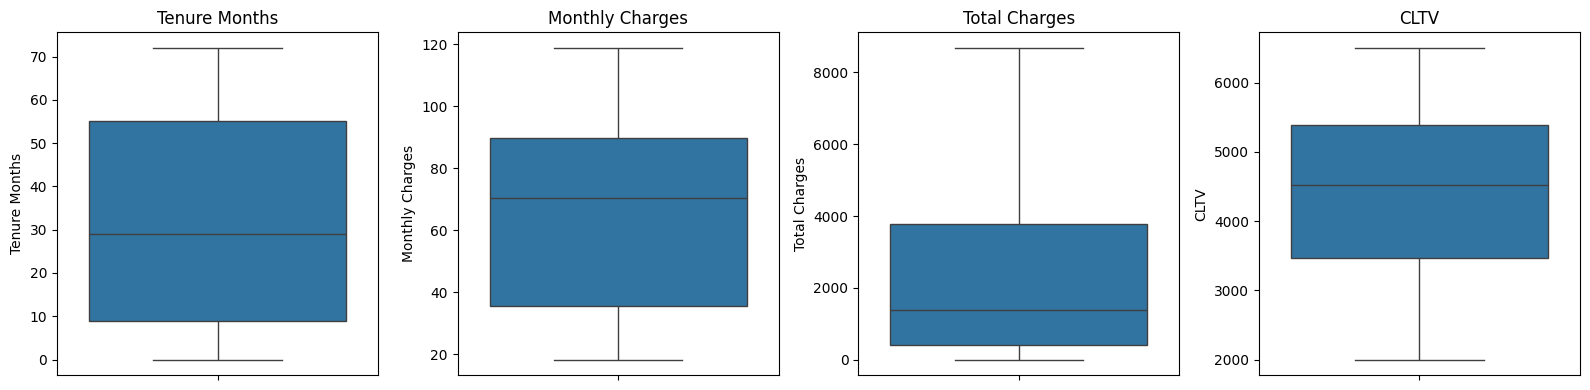

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


print("\n" + "=" * 70, "\n3. ВЫБРОСЫ (правило 1.5*IQR и |z|>3)\n", "=" * 70)
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges", "CLTV"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    # z показывает, на сколько стандартных отклонений значение отстоит от среднего
    z = (df[c] - df[c].mean()) / df[c].std()
    rows.append({"feature": c, "lower": round(lo, 2), "upper": round(hi, 2),
                 "n_IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
                 "n_|z|>3": int((z.abs() > 3).sum())})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.savefig(f"boxplots.png", dpi=120)
plt.show()
plt.close()

**4. Анализ дубликатов**

In [ ]:
print("\n" + "=" * 70, "\n4. ДУБЛИКАТЫ\n", "=" * 70)
print("Полностью дублирующихся строк:", df.duplicated().sum())
print("Дубликатов CustomerID:", df["CustomerID"].duplicated().sum())
cols_wo_id = [c for c in df.columns if c != "CustomerID"]
print("Дубликатов по всем признакам кроме CustomerID:", df.duplicated(subset=cols_wo_id).sum())
df = df.drop_duplicates().reset_index(drop=True)


4. ДУБЛИКАТЫ
Полностью дублирующихся строк: 0
Дубликатов CustomerID: 0
Дубликатов по всем признакам кроме CustomerID: 0


**5. Цифровизация признаков**

In [ ]:
LEAKAGE = ["Churn Label", "Churn Score", "CLTV", "Churn Reason"]

print("\n" + "=" * 70, "\n5. ЦИФРОВИЗАЦИЯ\n", "=" * 70)
work = df.drop(columns=["CustomerID", "Count", "Country", "State", "City",
                        "Zip Code", "Lat Long"] + LEAKAGE, errors="ignore").copy()

# 'No internet service' / 'No phone service' по смыслу равны 'No'
work = work.replace({"No internet service": "No", "No phone service": "No"})

# Бинарные Yes/No -> 1/0
for c in work.columns:
    if set(work[c].dropna().unique()) <= {"Yes", "No"}:
        work[c] = work[c].map({"Yes": 1, "No": 0})
work["Gender"] = work["Gender"].map({"Male": 1, "Female": 0})

# Contract - порядковый признак
work["Contract"] = work["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})

# Номинальные -> one-hot (drop_first, чтобы не создавать идеальную коллинеарность)
work = pd.get_dummies(work, columns=["Internet Service", "Payment Method"],
                      drop_first=True, dtype=int)
print("Типы после кодирования:\n", work.dtypes.value_counts())
print("Остались нечисловые столбцы:", list(work.select_dtypes("object").columns))


5. ЦИФРОВИЗАЦИЯ
Типы после кодирования:
 int64      21
float64     4
Name: count, dtype: int64
Остались нечисловые столбцы: []


**6. Мультиколлинеарность**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant


print("\n" + "=" * 70, "\n6. МУЛЬТИКОЛЛИНЕАРНОСТЬ\n", "=" * 70)
X = work.drop(columns=[TARGET])

corr = X.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True)
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.savefig(f"corr_matrix.png", dpi=120)
plt.close()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("r").reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
print("Пары с |r| > 0.7:")
print(pairs[pairs.r.abs() > 0.7].sort_values("r", key=abs, ascending=False).to_string(index=False))


def calc_vif(frame):
    Xc = add_constant(frame.astype(float))
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=frame.columns).sort_values(ascending=False)


vif = calc_vif(X)
print("\nVIF (>10 - сильная мультиколлинеарность):")
print(vif.round(2).to_string())

# Итеративное удаление признаков с VIF > 10
X_red = X.copy()
dropped = []
while True:
    v = calc_vif(X_red)
    if v.iloc[0] <= 10:
        break
    dropped.append((v.index[0], round(v.iloc[0], 1)))
    X_red = X_red.drop(columns=v.index[0])
print("\nУдалены при VIF > 10:", dropped)
print("Итоговые VIF:\n", calc_vif(X_red).round(2).to_string())


6. МУЛЬТИКОЛЛИНЕАРНОСТЬ
Пары с |r| > 0.7:
      feature_1                    feature_2         r
       Latitude                    Longitude -0.876779
  Tenure Months                Total Charges  0.826178
Monthly Charges Internet Service_Fiber optic  0.787066
Monthly Charges          Internet Service_No -0.763557

VIF (>10 - сильная мультиколлинеарность):
Monthly Charges                           865.51
Internet Service_Fiber optic              148.32
Internet Service_No                       104.32
Phone Service                              34.89
Streaming Movies                           24.13
Streaming TV                               24.08
Total Charges                              10.76
Tenure Months                               7.53
Multiple Lines                              7.27
Device Protection                           6.93
Online Backup                               6.79
Tech Support                                6.47
Online Security                             6.34
Lo

**7. Изменение размерности типа данных**

In [ ]:
# Объединяем отобранные после VIF признаки и целевую переменную
reduced_df = pd.concat([X_red, work[TARGET]], axis=1)

# Оптимизация типов данных для уменьшения размера в памяти
for col in reduced_df.select_dtypes(include=['integer']).columns:
    reduced_df[col] = pd.to_numeric(reduced_df[col], downcast="integer")

for col in reduced_df.select_dtypes(include=['float']).columns:
    reduced_df[col] = pd.to_numeric(reduced_df[col], downcast="float")

# Сохранение оптимизированных датасетов
work.to_csv("telco_encoded_full.csv", index=False)
reduced_df.to_csv("telco_encoded_vif_reduced.csv", index=False)

print("Размерность итогового датасета:", reduced_df.shape)
reduced_df.info()
print("\nБаланс классов целевой переменной:\n", work[TARGET].value_counts(normalize=True).round(3))

Размерность итогового датасета: (7043, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Latitude                                7043 non-null   float32
 1   Longitude                               7043 non-null   float32
 2   Gender                                  7043 non-null   int8   
 3   Senior Citizen                          7043 non-null   int8   
 4   Partner                                 7043 non-null   int8   
 5   Dependents                              7043 non-null   int8   
 6   Tenure Months                           7043 non-null   int8   
 7   Phone Service                           7043 non-null   int8   
 8   Multiple Lines                          7043 non-null   int8   
 9   Online Security                         7043 non-null   int8   
 10  Online Backup    

### Спецификация признаков (Data Dictionary) для исходного и обработанного датасетов


In [ ]:
import pandas as pd

raw_df = pd.read_excel("/content/Telco_customer_churn.xlsx")
raw_df.columns = raw_df.columns.str.strip()

# Спецификация для исходного датасета
original_features_info = {
    "CustomerID": "Уникальный идентификатор клиента",
    "Count": "Технический счетчик (всегда равен 1)",
    "Country": "Страна проживания клиента",
    "State": "Штат проживания клиента",
    "City": "Город проживания клиента",
    "Zip Code": "Почтовый индекс",
    "Lat Long": "Координаты (строка)",
    "Latitude": "Широта местоположения",
    "Longitude": "Долгота местоположения",
    "Gender": "Пол клиента",
    "Senior Citizen": "Является ли клиент пожилым гражданином (Yes/No)",
    "Partner": "Наличие супруга/партнера (Yes/No)",
    "Dependents": "Наличие иждивенцев (Yes/No)",
    "Tenure Months": "Количество месяцев, в течение которых клиент пользуется услугами",
    "Phone Service": "Подключена ли телефонная связь (Yes/No)",
    "Multiple Lines": "Подключено ли несколько телефонных линий (Yes/No/No phone service)",
    "Internet Service": "Тип интернет-провайдера (DSL/Fiber optic/No)",
    "Online Security": "Услуга онлайн-безопасности (Yes/No/No internet service)",
    "Online Backup": "Услуга резервного копирования (Yes/No/No internet service)",
    "Device Protection": "Страховка оборудования (Yes/No/No internet service)",
    "Tech Support": "Услуга технической поддержки (Yes/No/No internet service)",
    "Streaming TV": "Услуга стримингового телевидения (Yes/No/No internet service)",
    "Streaming Movies": "Услуга стриминга кино (Yes/No/No internet service)",
    "Contract": "Тип контракта (Month-to-month/One year/Two year)",
    "Paperless Billing": "Электронный биллинг (Yes/No)",
    "Payment Method": "Способ оплаты услуг",
    "Monthly Charges": "Ежемесячный платеж клиента",
    "Total Charges": "Общая сумма платежей за все время",
    "Churn Label": "Текстовая метка оттока (Yes/No)",
    "Churn Value": "Бинарная целевая переменная оттока (1 - ушел, 0 - остался)",
    "Churn Score": "Показатель вероятности оттока от внутренней системы (0-100)",
    "CLTV": "Прогнозируемая пожизненная ценность клиента",
    "Churn Reason": "Причина ухода клиента (заполнено только для ушедших)"
}

# Строим интерактивную таблицу соответствия признаков
rows_spec = []
for col in raw_df.columns:
    desc = original_features_info.get(col, "-")
    old_type = str(raw_df[col].dtype)

    # Проверяем, остался ли признак в финальном датасете (после VIF-фильтрации)
    in_final = col in reduced_df.columns
    new_type = str(reduced_df[col].dtype) if in_final else "Удален (или исключен)"

    # Формируем комментарий по трансформации
    comment = ""
    if not in_final:
        if col in ["CustomerID", "Count", "Country", "State", "City", "Zip Code", "Lat Long"]:
            comment = "Исключен (высокая кардинальность / неинформативен / дублирует координаты)"
        elif col in ["Churn Label", "Churn Score", "CLTV", "Churn Reason"]:
            comment = "Исключен (утечка целевой переменной / доступно только постфактум)"
        elif col in ["Monthly Charges", "Total Charges"]:
            comment = "Удален в ходе VIF-фильтрации из-за высокой мультиколлинеарности"
    else:
        if col == "Gender":
            comment = "Кодирование: 1 - Male, 0 - Female"
        elif col in ["Senior Citizen", "Partner", "Dependents", "Phone Service", "Paperless Billing", "Churn Value"]:
            comment = "Кодирование: 1 - Yes, 0 - No"
        elif col == "Contract":
            comment = "Порядковое кодирование: 0 - Month-to-month, 1 - One year, 2 - Two year"
        elif col in ["Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies", "Multiple Lines"]:
            comment = "Кодирование: 1 - Yes, 0 - No/No service (объединены)"
        elif col in ["Latitude", "Longitude"]:
            comment = "Сохранен как вещественный признак, тип приведен к float32"

    # Дополнительно отметим OHE-колонки, которых не было в исходном датасете напрямую
    rows_spec.append({
        "Название атрибута (исходное)": col,
        "Описание": desc,
        "Исходный формат": old_type,
        "Финальный формат": new_type,
        "Комментарий / Трансформация": comment
    })

# Добавим в спецификацию созданные через One-Hot Encoding признаки
for col in reduced_df.columns:
    if col not in raw_df.columns:
        rows_spec.append({
            "Название атрибута (исходное)": f"{col}",
            "Описание": f"Бинарный флаг для категории '{col}'\n(Создан из " + ("Internet Service" if "Internet" in col else "Payment Method") + ")",
            "Исходный формат": "-",
            "Финальный формат": str(reduced_df[col].dtype),
            "Комментарий / Трансформация": "One-Hot кодирование (1 - да, 0 - нет)"
        })

df_spec = pd.DataFrame(rows_spec)
pd.set_option('display.max_rows', len(df_spec))
display(df_spec)

,Название атрибута (исходное),Описание,Исходный формат,Финальный формат,Комментарий / Трансформация
0,CustomerID,Уникальный идентификатор клиента,object,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
1,Count,Технический счетчик (всегда равен 1),int64,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
2,Country,Страна проживания клиента,object,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
3,State,Штат проживания клиента,object,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
4,City,Город проживания клиента,object,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
5,Zip Code,Почтовый индекс,int64,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
6,Lat Long,Координаты (строка),object,Удален (или исключен),Исключен (высокая кардинальность / неинформати...
7,Latitude,Широта местоположения,float64,float32,"Сохранен как вещественный признак, тип приведе..."
8,Longitude,Долгота местоположения,float64,float32,"Сохранен как вещественный признак, тип приведе..."
9,Gender,Пол клиента,object,int8,"Кодирование: 1 - Male, 0 - Female"


**Обработанные датасеты для дальнейшей работы**

In [ ]:
# В вашей зоне ответственности мы сохраняем датасеты БЕЗ масштабирования,
# чтобы избежать утечки данных (Data Leakage) при последующей валидации моделей.
# Коллеги сами применят MinMaxScaler строго к тренировочным выборкам после разбиения.

target_column = "Churn Value"

# 1. Полный датасет (все закодированные признаки, включая коллинеарные)
full_df = work.copy()

# 2. Редуцированный датасет (после удаления мультиколлинеарности через VIF)
vif_reduced_df = reduced_df.copy()

# Сохраняем итоговые чистые датасеты в исходном масштабе
full_df.to_csv("telco_encoded_full.csv", index=False)
vif_reduced_df.to_csv("telco_encoded_vif_reduced.csv", index=False)

print("=== Датасеты для передачи коллегам успешно сохранены! ===")
print(f"1. Полный датасет (Full): {full_df.shape} (для древесных моделей)")
print(f"2. Редуцированный датасет (VIF-Reduced): {vif_reduced_df.shape} (для линейных моделей и SPlit/SPXY)")
print(f"Баланс классов целевой переменной: {full_df[target_column].value_counts(normalize=True).round(3).to_dict()}")

=== Универсальные датасеты успешно сохранены! ===
1. Полный набор (Full): 24 признаков (содержит Monthly/Total Charges)
2. Очищенный набор (VIF-Reduced): 22 признаков
Распределение классов (одинаковое для обоих): {0: 0.735, 1: 0.265}
